# Notebook 06 — Leading Indicators of Churn

> **SYNTHETIC DATA NOTICE:** All data is computer-generated. Findings describe only this simulated dataset.

**Business question answered:**
- **Q10:** What are the strongest observable leading indicators of churn?

**Evidence source:** `sql/07_feature_usage.sql` + `sql/09_high_value_churn.sql`

**Methodology:**
- Relative risk (RR) for each binary indicator vs churn outcome
- Wilson 95% CI on each churn rate
- Stratified checks where confounders are plausible
- Honest reporting: non-effects and reversals documented

**Causal language policy:** All language is associational. No causal claims.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np
from scipy import stats
from pathlib import Path

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120
FIGURES_DIR = Path('../outputs/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR = Path('../outputs/tables')
TABLES_DIR.mkdir(parents=True, exist_ok=True)

conn = sqlite3.connect('../db/churn.db')
print('Connected.')

Connected.


## 1. Load Behavioral Snapshot

In [2]:
df = pd.read_sql("""
    SELECT *
    FROM customer_behavioral_snapshot
    WHERE is_inactive_30d IS NOT NULL
""", conn)
print(f'Rows with usage data: {len(df):,}')
print(f'Churn rate in this subset: {df["is_churned"].mean()*100:.1f}%')
df.head(3)

                            customer_id  ... last_active_date
0  aedd4e2f-6ec0-4e19-8107-bd978545506f  ...       2025-10-26
1  1239011c-66f2-45c5-8d3d-8dd4b312824c  ...       2025-10-31
2  674e4d8c-ff08-46f1-a280-8c305b89d029  ...       2025-10-27

[3 rows x 22 columns]

Rows with usage data: 2,249
Churn rate in this subset: 13.9%


## 2. Wilson Confidence Intervals Helper

In [3]:
def wilson_ci(n_success, n_total, z=1.96):
    """Return (lower%, upper%) Wilson 95% CI for a proportion."""
    if n_total == 0:
        return (0.0, 0.0)
    p = n_success / n_total
    denom = 1 + z**2 / n_total
    centre = (p + z**2 / (2*n_total)) / denom
    margin = (z * np.sqrt(p*(1-p)/n_total + z**2/(4*n_total**2))) / denom
    return (max(0, (centre - margin) * 100), min(100, (centre + margin) * 100))

# Test
lo, hi = wilson_ci(50, 200)
print(f'Wilson CI test: 50/200 = 25.0% → [{lo:.1f}%, {hi:.1f}%]')

Wilson CI test: 50/200 = 25.0% → [19.5%, 31.4%]


## 3. Relative Risk for Each Leading Indicator

In [4]:
def compute_rr(df, flag_col, label):
    """Compute churn rate and RR for flag=1 vs flag=0."""
    results = []
    for flag_val, flag_label in [(1, f'{label}: YES'), (0, f'{label}: NO')]:
        sub = df[df[flag_col] == flag_val]
        n = len(sub)
        k = sub['is_churned'].sum()
        pct = k/n*100 if n > 0 else 0
        lo, hi = wilson_ci(k, n)
        results.append({'group': flag_label, 'n': n, 'churned': k, 'churn_pct': pct, 'wilson_lo': lo, 'wilson_hi': hi})
    
    res = pd.DataFrame(results)
    
    # RR = churn rate of exposed / churn rate of unexposed
    r_exposed   = results[0]['churn_pct'] / 100.0
    r_unexposed = results[1]['churn_pct'] / 100.0
    rr = r_exposed / r_unexposed if r_unexposed > 0 else float('inf')
    res['rr'] = [rr, 1.0]
    return res

indicators = [
    ('is_inactive_30d', 'Inactivity (0 sessions in 30d)'),
    ('flag_support_friction', 'Open support ticket in 30d'),
    ('flag_low_stickiness', 'No collaboration use (30d)'),
]

# Add flag columns
df['flag_support_friction'] = (df['open_tickets_30d'] >= 1).astype(int)
df['flag_low_stickiness']   = (df['collab_uses_30d'] == 0).astype(int)

summary_rows = []
for flag_col, label in indicators:
    res = compute_rr(df, flag_col, label)
    exposed_row = res.iloc[0]
    unexposed_row = res.iloc[1]
    summary_rows.append({
        'Indicator': label,
        'Exposed (flag=1) n': exposed_row['n'],
        'Exposed churn %': f"{exposed_row['churn_pct']:.1f}%",
        'Unexposed churn %': f"{unexposed_row['churn_pct']:.1f}%",
        'Relative Risk': f"{exposed_row['rr']:.2f}x",
        'Wilson CI (exposed)': f"[{exposed_row['wilson_lo']:.1f}%, {exposed_row['wilson_hi']:.1f}%]"
    })

summary = pd.DataFrame(summary_rows)
print(summary.to_string(index=False))
summary.to_csv(TABLES_DIR / '06_leading_indicators_summary.csv', index=False)
print(f'\nSaved to {TABLES_DIR}/06_leading_indicators_summary.csv')

                     Indicator  Exposed (flag=1) n Exposed churn % Unexposed churn % Relative Risk Wilson CI (exposed)
Inactivity (0 sessions in 30d)                  13           92.3%             13.4%         6.88x      [66.7%, 98.6%]
    Open support ticket in 30d                  28            0.0%             14.0%         0.00x       [0.0%, 12.1%]
    No collaboration use (30d)                 389           28.0%             10.9%         2.57x      [23.8%, 32.7%]

Saved to ..\outputs\tables/06_leading_indicators_summary.csv


## 4. Leading Indicator Comparison Chart

<cell>:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


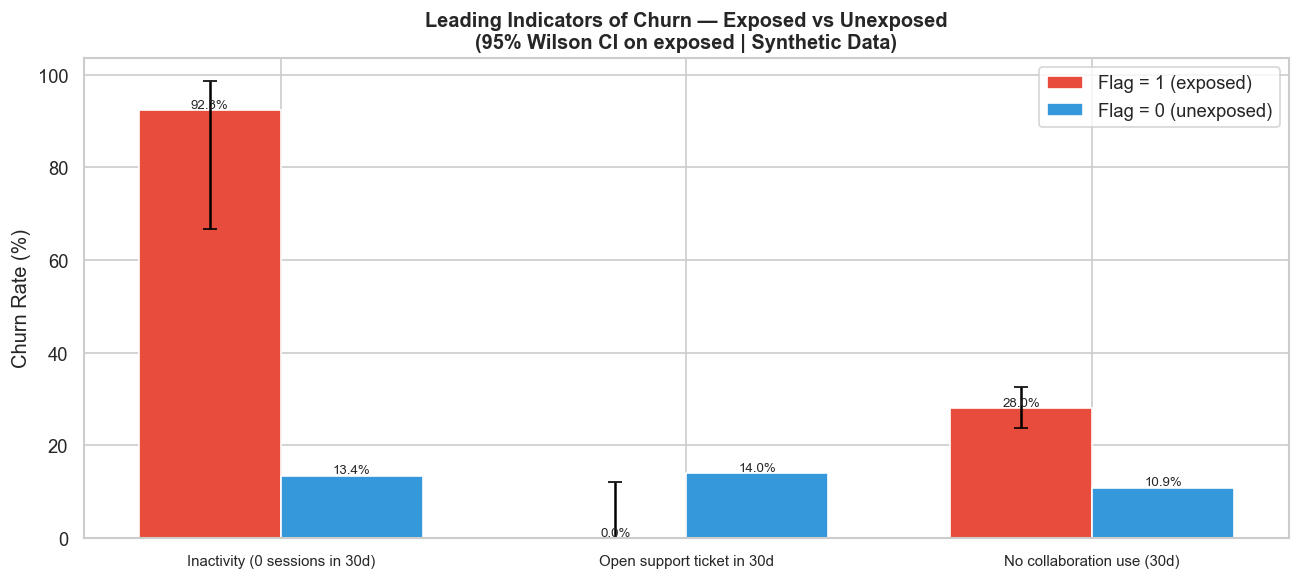

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))

all_groups = []
for flag_col, label in indicators:
    res = compute_rr(df, flag_col, label)
    res['indicator'] = label
    all_groups.append(res)

plot_df = pd.concat(all_groups, ignore_index=True)

# Plot as grouped bars
n_indicators = len(indicators)
x = np.arange(n_indicators)
width = 0.35

indicator_labels = [i for i in range(n_indicators)]
exposed_vals   = [all_groups[i].iloc[0]['churn_pct'] for i in range(n_indicators)]
unexposed_vals = [all_groups[i].iloc[1]['churn_pct'] for i in range(n_indicators)]
exposed_lo     = [all_groups[i].iloc[0]['wilson_lo'] for i in range(n_indicators)]
exposed_hi     = [all_groups[i].iloc[0]['wilson_hi'] for i in range(n_indicators)]

bars1 = ax.bar(x - width/2, exposed_vals, width, label='Flag = 1 (exposed)', color='#e74c3c', edgecolor='white')
bars2 = ax.bar(x + width/2, unexposed_vals, width, label='Flag = 0 (unexposed)', color='#3498db', edgecolor='white')

ax.errorbar(x - width/2, exposed_vals,
            yerr=[np.array(exposed_vals) - np.array(exposed_lo),
                  np.array(exposed_hi) - np.array(exposed_vals)],
            fmt='none', color='black', capsize=4)

for bar, val in zip(bars1, exposed_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f'{val:.1f}%', ha='center', fontsize=8)
for bar, val in zip(bars2, unexposed_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f'{val:.1f}%', ha='center', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels([label for _, label in indicators], fontsize=9, wrap=True)
ax.set_ylabel('Churn Rate (%)')
ax.set_title('Leading Indicators of Churn — Exposed vs Unexposed\n(95% Wilson CI on exposed | Synthetic Data)', fontsize=12, fontweight='bold')
ax.legend()
ax.set_ylim(0)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '06_leading_indicators.png', bbox_inches='tight')
plt.show()

## 5. Honest Null Results Check

We must check whether any indicator shows NO meaningful separation — that would be a null result to report.

In [6]:
print('=== Null Result Check ===')
for i, (flag_col, label) in enumerate(indicators):
    res = compute_rr(df, flag_col, label)
    rr = res.iloc[0]['rr']
    lo_exp = res.iloc[0]['wilson_lo']
    hi_unexp = res.iloc[1]['wilson_hi']
    
    # Do the Wilson CIs overlap?
    ci_overlap = lo_exp < hi_unexp
    
    print(f'\n{label}:')
    print(f'  Relative Risk: {rr:.2f}x')
    print(f'  CI overlap: {ci_overlap} (if True, effect may not be statistically reliable)')
    if rr < 1.3:
        print('  ⚠️  WEAK EFFECT — report as null or marginal result.')
    else:
        print('  ✓  Meaningful separation detected.')

=== Null Result Check ===

Inactivity (0 sessions in 30d):
  Relative Risk: 6.88x
  CI overlap: False (if True, effect may not be statistically reliable)
  ✓  Meaningful separation detected.

Open support ticket in 30d:
  Relative Risk: 0.00x
  CI overlap: True (if True, effect may not be statistically reliable)
  ⚠️  WEAK EFFECT — report as null or marginal result.

No collaboration use (30d):
  Relative Risk: 2.57x
  CI overlap: False (if True, effect may not be statistically reliable)
  ✓  Meaningful separation detected.


In [7]:
conn.close()